# P3｜最終測試與統計分析

**已依事前凍結設定執行唯一一次 Final Test，不應再次執行。** `FINAL_TEST_EVALUATED.json` 記錄 292 筆測試完成狀態。
Final Test 前已固定 Elastic Net + QualityArea + log1p、alpha=0.0031622776601683794、l1_ratio=0.1，以及 MAE threshold=15,000 USD；Final Test 沒有用於重選模型或調參。

## 已完成產出
- 最終 baseline 比較：MAE、RMSE（USD）、R²。
- 最終線性模型 vs Random Forest 的 paired bootstrap MAE gap CI 與 paired permutation 檢定。
- 全部最終特徵的標準化係數、bootstrap 95% CI、近似 p-value、VIF。
- 至少 3 個最大誤差案例、預測散布與残差圖。

In [1]:
from pathlib import Path
import json, hashlib, platform, time, warnings, inspect
import numpy as np
import pandas as pd
import scipy, sklearn
from scipy.special import boxcox1p
from scipy.stats import skew
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/outputs/p1/data_split.csv').exists()), None)
assert ROOT is not None, '請從專案資料夾或 notebooks/ 執行。'
MODEL_ROOT = ROOT / 'model'
OUTPUT = MODEL_ROOT / 'results/tables/model_evaluation'
SEED = 42
# 初始資料與候選設定沿用 03；本 cell 只載入 training，Final Test 於 freeze guard 後讀取一次。
REMOVE_P1_OUTLIERS = True
SEARCH_APPROVED = True
ENVIRONMENT_APPROVED = True
RUN_EXPERIMENTS = True
N_JOBS = 1
print('Project:', ROOT)
print('Python:', platform.python_version(), 'sklearn:', sklearn.__version__)


Project: /data/chingyufan/Data_mining/HW1/Data-Mining-HW1
Python: 3.11.8 sklearn: 1.4.1.post1


In [2]:
import csv
split_path = ROOT / 'data/outputs/p1/data_split.csv'
raw_path = ROOT / 'data/raw_data_FromKaggle/train.csv'
splits = pd.read_csv(split_path)
assert splits['Id'].is_unique
assert set(splits['split']) == {'train', 'test'}
training_ids = set(splits.loc[splits['split'].eq('train'), 'Id'])
with raw_path.open(encoding='utf-8-sig', newline='') as f:
    rows = [row for row in csv.DictReader(f) if int(row['Id']) in training_ids]
train = pd.DataFrame(rows).replace({'': np.nan, 'NA': np.nan, 'None': np.nan})
assert len(train) == len(training_ids)
for col in train:
    if col not in ['Id']:
        try:
            train[col] = pd.to_numeric(train[col])
        except (ValueError, TypeError):
            pass
train['Id'] = pd.to_numeric(train['Id']).astype(int)
train = train.merge(splits.loc[splits['split'].eq('train'), ['Id', 'cv_fold']],
                    on='Id', validate='one_to_one').sort_values('Id').reset_index(drop=True)
assert train['cv_fold'].notna().all()
assert REMOVE_P1_OUTLIERS is not None, '請先確認是否沿用 P1 異常值刪除。'
if REMOVE_P1_OUTLIERS:
    assert set(train.loc[(train.GrLivArea > 4000) & (train.SalePrice < 300000), 'Id']) == {524, 1299}
    train = train.loc[~train.Id.isin([524, 1299])].reset_index(drop=True)
EXCLUDED = ['Id', 'SalePrice', 'cv_fold', 'YrSold', 'MoSold', 'SaleType', 'SaleCondition',
            'Utilities', 'GarageYrBlt']
X = train.drop(columns=EXCLUDED)
y = train['SalePrice'].astype(float)
fold_ids = train['cv_fold'].astype(int).to_numpy()
cv = list(PredefinedSplit(fold_ids).split())
assert set(fold_ids) == set(range(5))
assert y.gt(0).all()
assert not set(train.Id) & set(splits.loc[splits['split'].eq('test'), 'Id'])
display(train.groupby('cv_fold').size().rename('validation_rows').to_frame())
print('Training:', X.shape, '| Final Test 未載入')


,validation_rows
cv_fold,
0.0,233
1.0,234
2.0,234
3.0,232
4.0,233


Training: (1166, 73) | Final Test 未載入


In [3]:
ORDINAL = {'Street': {'Grvl': 0, 'Pave': 1, 'None': 0}, 'Alley': {'Grvl': 1, 'Pave': 2, 'None': 0}, 'LotShape': {'Reg': 3, 'IR1': 2, 'IR2': 1, 'IR3': 0, 'None': 0}, 'LandSlope': {'Gtl': 2, 'Mod': 1, 'Sev': 0, 'None': 0}, 'ExterQual': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'ExterCond': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'BsmtQual': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'BsmtCond': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'BsmtExposure': {'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1, 'None': 0}, 'BsmtFinType1': {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1, 'None': 0}, 'BsmtFinType2': {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1, 'None': 0}, 'HeatingQC': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'CentralAir': {'Y': 1, 'N': 0, 'None': 0}, 'KitchenQual': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'Functional': {'Typ': 7, 'Min1': 6, 'Min2': 5, 'Mod': 4, 'Maj1': 3, 'Maj2': 2, 'Sev': 1, 'Sal': 0, 'None': 0}, 'FireplaceQu': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'GarageFinish': {'Fin': 3, 'RFn': 2, 'Unf': 1, 'None': 0}, 'GarageQual': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'GarageCond': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'PavedDrive': {'Y': 2, 'P': 1, 'N': 0, 'None': 0}, 'PoolQC': {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}, 'Fence': {'GdPrv': 4, 'MnPrv': 3, 'GdWo': 2, 'MnWw': 1, 'None': 0}}


In [4]:
class P1FoldPreparation(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.frontage_by_neighborhood_ = X.groupby('Neighborhood')['LotFrontage'].median()
        self.frontage_global_ = X['LotFrontage'].median()
        self.modes_ = {}
        for col in X.select_dtypes(include='object'):
            mode = X[col].mode()
            self.modes_[col] = mode.iloc[0] if len(mode) else 'None'
        return self

    def transform(self, X):
        out = X.copy()
        for col in ['PoolQC','MiscFeature','Alley','Fence','FireplaceQu',
                    'GarageType','GarageFinish','GarageQual','GarageCond','MasVnrType']:
            out[col] = out[col].fillna('None')
        for col in ['GarageArea','GarageCars','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF',
                    'TotalBsmtSF','BsmtFullBath','BsmtHalfBath','MasVnrArea']:
            out[col] = out[col].fillna(0)
        for col in ['BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2']:
            has_basement = out['TotalBsmtSF'] > 0
            out.loc[out[col].isna() & has_basement, col] = self.modes_[col]
            out[col] = out[col].fillna('None')
        out['LotFrontage'] = out['LotFrontage'].fillna(
            out.Neighborhood.map(self.frontage_by_neighborhood_)).fillna(self.frontage_global_)
        for col in ['MSZoning','Electrical','KitchenQual','Exterior1st','Exterior2nd']:
            out[col] = out[col].fillna(self.modes_[col])
        out['Functional'] = out['Functional'].fillna('Typ')
        for col, mapping in ORDINAL.items():
            values = out[col].map(mapping)
            if values.isna().any():
                raise ValueError(f'{col}: 未定義有序類別 {out.loc[values.isna(), col].unique()}')
            out[col] = values.astype(float)
        out['MSSubClass'] = out['MSSubClass'].astype(str)
        return out

class FoldBoxCox(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        a = np.asarray(X, dtype=float)
        self.n_features_in_ = a.shape[1]
        s = np.array([skew(a[:, j]) if np.ptp(a[:, j]) > 0 else 0
                      for j in range(a.shape[1])])
        self.selected_ = np.flatnonzero(np.abs(s) > .75)
        return self

    def transform(self, X):
        a = np.asarray(X, dtype=float).copy()
        if a.shape[1] != self.n_features_in_:
            raise ValueError('數值欄位數不同')
        if self.selected_.size:
            if np.any(a[:, self.selected_] < 0):
                raise ValueError('P1 Box-Cox 欄位出現負值，需確認處理規則')
            a[:, self.selected_] = boxcox1p(a[:, self.selected_], .15)
        return a

onehot_kwargs = {'handle_unknown': 'ignore'}
onehot_kwargs['sparse_output' if 'sparse_output' in inspect.signature(OneHotEncoder).parameters else 'sparse'] = False

def make_pipeline(model, single=False, trivial=False):
    if single:
        return Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('scale', RobustScaler()), ('model', model)])
    if trivial:
        return Pipeline([('impute', SimpleImputer(strategy='median')), ('model', model)])
    numeric = Pipeline([('impute', SimpleImputer(strategy='median')),
                        ('boxcox', FoldBoxCox()), ('scale', RobustScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                            ('onehot', OneHotEncoder(**onehot_kwargs))])
    columns = ColumnTransformer([
        ('numeric', numeric, make_column_selector(dtype_include=np.number)),
        ('categorical', categorical, make_column_selector(dtype_include=object))])
    return Pipeline([('p1', P1FoldPreparation()), ('columns', columns), ('model', model)])


In [5]:
class StableOLS(BaseEstimator):
    def fit(self, X, y):
        a = np.asarray(X, dtype=float)
        self.n_features_in_ = a.shape[1]
        self.x_mean_ = a.mean(axis=0)
        self.y_mean_ = float(np.mean(y))
        centered = a - self.x_mean_
        self.rcond_ = max(centered.shape) * np.finfo(float).eps
        self.coef_, _, self.rank_, self.singular_ = np.linalg.lstsq(
            centered, np.asarray(y) - self.y_mean_, rcond=self.rcond_)
        self.intercept_ = self.y_mean_ - self.x_mean_ @ self.coef_
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

def candidates():
    assert SEARCH_APPROVED
    for name, model, feature_kind in [
        ('Mean', DummyRegressor(strategy='mean'), 'trivial'),
        ('SingleOLS', LinearRegression(), 'single'),
        ('OLS', StableOLS(), 'raw'),
        ('Ridge', Ridge(), 'raw'),
        ('Lasso', Lasso(max_iter=100000), 'raw'),
        ('ElasticNet', ElasticNet(max_iter=100000), 'raw'),
        ('RandomForest', RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1), 'raw')]:
        for target in (['raw'] if name == 'Mean' else ['raw', 'log1p']):
            base = make_pipeline(clone(model), single=feature_kind=='single', trivial=feature_kind=='trivial')
            estimator = (TransformedTargetRegressor(regressor=base, func=np.log1p, inverse_func=np.expm1)
                         if target == 'log1p' else base)
            prefix = 'regressor__model__' if target == 'log1p' else 'model__'
            grid = {}
            if name == 'Ridge':
                grid = {prefix+'alpha': np.logspace(-3, 4, 15)}
            elif name in ['Lasso', 'ElasticNet']:
                grid = {prefix+'alpha': np.logspace(-1, 4, 11) if target == 'raw' else np.logspace(-5, 0, 11)}
                if name == 'ElasticNet':
                    grid[prefix+'l1_ratio'] = [.1, .5, .9]
            elif name == 'RandomForest':
                grid = {prefix+'max_depth': [None, 10], prefix+'min_samples_leaf': [1, 3],
                        prefix+'max_features': [1.0, .7]}
            yield name, target, estimator, grid, feature_kind

SCORING = {'MAE': 'neg_mean_absolute_error',
           'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}


## 1. Freeze 設定

05 已完成 P2 特徵比較，06 已完成 Model Choice。本檔在讀取 Final Test 前固定所有設定。
Final Model 為 Elastic Net + H1_QualityArea + log1p；alpha=0.0031622776601683794、l1_ratio=0.1。單特徵與 Random Forest baseline 的 target/參數均由 training CV 決定；平均房價 baseline 固定原始 USD。
事前 MAE 門檻為 15,000 USD，依 training CV mean + 2 SD = 14,984.60 USD 向上取整，沒有使用 Final Test 倒推門檻。

In [6]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import ParameterGrid
from sklearn.exceptions import ConvergenceWarning
import subprocess

ABLATION_OUTPUT = MODEL_ROOT / 'results/tables/feature_ablation'
ABLATION_OUTPUT.mkdir(parents=True, exist_ok=True)
NUMERIC_SCOPE = [c for c in X.select_dtypes(include=np.number).columns if c != 'MSSubClass']
assert len(NUMERIC_SCOPE)==32
CONTINUOUS_MI = [c for c in X if c.endswith('SF') or c in ['LotFrontage','LotArea','GrLivArea','MasVnrArea','GarageArea','MiscVal','TotalBsmtSF']]
SET_NAMES = ['A_Raw','B_MI15','B_MI20','B_Pearson20','C_Engineered',
             'H1_QualityArea','H2_RawLotArea','H2_LogLotArea','H3_TotalSF']
LOG_GRIDS = {'Ridge':{'alpha':np.logspace(-3,4,15)},
             'Lasso':{'alpha':np.logspace(-5,0,11)},
             'ElasticNet':{'alpha':np.logspace(-5,0,11),'l1_ratio':[.1,.5,.9]}}
plan={'feature_sets':SET_NAMES,'models':list(LOG_GRIDS),'target':'log1p',
      'primary_selection_metric':'MAE_USD','hypothesis_metric':'RMSE_USD',
      'hypothesis_primary_model':'Ridge','hypothesis_fixed_alpha':10.0,
      'H3_relative_RMSE_tolerance':.02,'H3_dimension_rule':'encoded dimension smaller in every fold',
      'folds':5,'seed':42,'MI_n_neighbors':3,'Pearson_candidate_count':32,
      'boxcox_protected':['QualityArea','LogLotArea'],
      'test_evaluated':False,'P2_source_commit':subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT).decode().strip()}
(ABLATION_OUTPUT/'experiment_plan.json').write_text(json.dumps(plan,ensure_ascii=False,indent=2))

class P2FeatureSet(BaseEstimator, TransformerMixin):
    def __init__(self, set_name='A_Raw'):
        self.set_name=set_name
    def fit(self, X, y=None):
        self.source_columns_=list(X.columns)
        self.ranking_=[]
        self.selected_=list(X.columns)
        if self.set_name in ['B_MI15','B_MI20','C_Engineered']:
            encoded=X.copy();discrete=[]
            for col in encoded:
                is_discrete=col not in CONTINUOUS_MI;discrete.append(is_discrete)
                if is_discrete:encoded[col]=pd.factorize(encoded[col].astype(str),sort=True)[0]
            scores=mutual_info_regression(encoded,np.asarray(y),discrete_features=discrete,n_neighbors=3,random_state=SEED)
            self.ranking_=sorted(zip(X.columns,scores),key=lambda pair:(-pair[1],pair[0]))
            self.selected_=[c for c,_ in self.ranking_[:15 if self.set_name=='B_MI15' else 20]]
        elif self.set_name=='B_Pearson20':
            scores=X[NUMERIC_SCOPE].corrwith(pd.Series(np.asarray(y),index=X.index)).abs().fillna(0)
            self.ranking_=sorted(scores.items(),key=lambda pair:(-pair[1],pair[0]))
            self.selected_=[c for c,_ in self.ranking_[:20]]
        return self
    def transform(self, X):
        out=X[self.selected_].copy()
        if self.set_name in ['H1_QualityArea','C_Engineered']:
            out['QualityArea']=X.OverallQual*X.GrLivArea
        if self.set_name in ['H2_LogLotArea','C_Engineered']:
            out['LogLotArea']=np.log1p(X.LotArea)
            if self.set_name=='H2_LogLotArea':out=out.drop(columns='LotArea')
        if self.set_name in ['H3_TotalSF','C_Engineered']:
            out['TotalSF']=X.TotalBsmtSF+X['1stFlrSF']+X['2ndFlrSF']
            if self.set_name=='H3_TotalSF':out=out.drop(columns=['TotalBsmtSF','1stFlrSF','2ndFlrSF'])
        return out

class NamedFoldNumerics(BaseEstimator, TransformerMixin):
    def __init__(self, protect=()):self.protect=protect
    def fit(self, X, y=None):
        self.columns_=list(X.columns)
        self.median_=X.median()
        filled=X.fillna(self.median_)
        assert not filled.isna().any().any()
        self.boxcox_columns_=[c for c in X if c not in self.protect and np.ptp(filled[c])>0 and abs(skew(filled[c]))>.75]
        return self
    def transform(self, X):
        out=X[self.columns_].fillna(self.median_).copy()
        for col in self.boxcox_columns_:
            if (out[col]<0).any():raise ValueError('Box-Cox 出現負值：'+col)
            out[col]=boxcox1p(out[col],.15)
        return out.to_numpy(dtype=float)

def make_feature_preprocessing(set_name):
    protect=('QualityArea','LogLotArea','LotArea') if set_name=='H2_RawLotArea' else ('QualityArea','LogLotArea')
    numeric=Pipeline([('boxcox',NamedFoldNumerics(protect=protect)),('scale',RobustScaler())])
    categorical=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(**onehot_kwargs))])
    columns=ColumnTransformer([
        ('numeric',numeric,make_column_selector(dtype_include=np.number)),
        ('categorical',categorical,make_column_selector(dtype_include=object))])
    return Pipeline([('p1',P1FoldPreparation()),('features',P2FeatureSet(set_name)),('columns',columns)])

def make_ablation_pipeline(model, set_name):
    return TransformedTargetRegressor(regressor=Pipeline([
        ('preprocess',make_feature_preprocessing(set_name)),('model',model)]),
        func=np.log1p,inverse_func=np.expm1)


In [7]:
FEATURE_DESIGN_COMPLETE = True
SETTINGS_FROZEN = True
FINAL_TEST_ALLOWED = True
# 2026-10-13：依 training-only CV、ablation 與 model-choice evidence 正式凍結；只允許一次 Final Test。
recommendations = pd.read_csv(ABLATION_OUTPUT / 'ablation_results.csv')
# Frozen from the P3 model-choice analysis before viewing Final Test: data structure and stability,
# with CV performance as supporting evidence. The completion marker prevents repeat evaluation.
recommendation = recommendations.loc[
    recommendations['set'].eq('H1_QualityArea') &
    recommendations.model.eq('ElasticNet')
].iloc[0]
FINAL_MODEL = 'ElasticNet'
FINAL_TARGET = 'log1p'
FINAL_FEATURE_SET = 'H1_QualityArea'
# 事前門檻：CV MAE mean + 2 SD = 14984.60 USD，向上取整為 15000 USD。
DECISION_MAE_USD = 15000.0
FINAL_OUTPUT = MODEL_ROOT / 'results/tables/final_test'
FINAL_FIGURES = MODEL_ROOT / 'results/figures/final_test'
assert FEATURE_DESIGN_COMPLETE and SETTINGS_FROZEN and FINAL_TEST_ALLOWED, (
    '尚未完成特徵／模型凍結：保持 Final Test 封存。')
assert FINAL_MODEL in ['Ridge','Lasso','ElasticNet']
assert FINAL_TARGET in ['raw','log1p']
assert DECISION_MAE_USD is not None and DECISION_MAE_USD > 0
assert not (FINAL_OUTPUT/'FINAL_TEST_EVALUATED.json').exists(), 'Final Test 已評估；請讀既有結果，不重複評分。'
cv_table = pd.read_csv(OUTPUT/'cv_model_comparison.csv')
ablation = recommendations.loc[(recommendations.model==FINAL_MODEL)&(recommendations['set']==FINAL_FEATURE_SET)].iloc[0]
chosen = pd.Series({'model':FINAL_MODEL,'target':FINAL_TARGET,'feature_set':FINAL_FEATURE_SET,
    'best_params':ablation['params'],'CV_MAE_mean':ablation.CV_MAE_USD_mean,
    'CV_MAE_std':ablation.CV_MAE_USD_std,'CV_RMSE_mean':ablation.CV_RMSE_USD_mean,
    'CV_RMSE_std':ablation.CV_RMSE_USD_std})
strong = cv_table.loc[cv_table.model=='RandomForest'].sort_values('CV_MAE_mean').iloc[0]
simple = cv_table.loc[cv_table.model=='SingleOLS'].sort_values('CV_MAE_mean').iloc[0]
mean = cv_table.loc[cv_table.model=='Mean'].iloc[0]
choices = [mean, simple, strong, chosen]
FINAL_OUTPUT.mkdir(parents=True,exist_ok=True)
FINAL_FIGURES.mkdir(parents=True,exist_ok=True)
freeze = {'final_model':FINAL_MODEL,'final_target':FINAL_TARGET,'decision_MAE_USD':DECISION_MAE_USD,
          'choices':[r.to_dict() for r in choices], 'feature_stage':'P2_feature_ablation_completed','final_feature_set':FINAL_FEATURE_SET}
(FINAL_OUTPUT/'freeze_settings.json').write_text(json.dumps(freeze,ensure_ascii=False,indent=2))


1816

## 2. 在 training 重訓，再一次性讀取並評分封存資料

Final Test 不剔除高誤差房屋、不重選特徵、不調參。計算誤差以 USD 為單位。
先寫入已啟動紀錄，避免重跑整份 Notebook 無意反覆使用 test；中途失敗需查看紀錄及既有輸出，不直接刪除 guard。


In [8]:
models = {}
for choice in choices:
    name,target=choice['model'],choice['target']
    if name==FINAL_MODEL:
        model={'Ridge':Ridge,'Lasso':lambda:Lasso(max_iter=100000),
               'ElasticNet':lambda:ElasticNet(max_iter=100000)}[name]()
        model.set_params(**json.loads(choice['best_params']))
        est=make_ablation_pipeline(model,FINAL_FEATURE_SET)
        kind='raw'
    else:
        spec=next(s for s in candidates() if s[0]==name and s[1]==target)
        _,_,est,_,kind=spec
        est.set_params(**json.loads(choice['best_params']))
    features=X[['GrLivArea']] if kind in ['trivial','single'] else X
    models[name]=est.fit(features,y)
(FINAL_OUTPUT/'FINAL_TEST_EVALUATED.json').write_text(json.dumps(
    {'status':'evaluation_started','freeze_sha256':hashlib.sha256((FINAL_OUTPUT/'freeze_settings.json').read_bytes()).hexdigest()},indent=2))
sealed_ids=set(splits.loc[splits['split'].eq('test'),'Id'])
with raw_path.open(encoding='utf-8-sig',newline='') as f:
    rows=[r for r in csv.DictReader(f) if int(r['Id']) in sealed_ids]
test=pd.DataFrame(rows).replace({'':np.nan,'NA':np.nan,'None':np.nan})
for col in test:
    try:test[col]=pd.to_numeric(test[col])
    except (ValueError,TypeError):pass
test=test.sort_values('Id').reset_index(drop=True)
assert len(test)==292 and not set(test.Id)&set(train.Id)
X_test=test[X.columns];y_test=test.SalePrice.astype(float)
result_rows=[];test_predictions=pd.DataFrame({'Id':test.Id,'actual_USD':y_test})
for choice in choices:
    name=choice['model'];features=X_test[['GrLivArea']] if name in ['Mean','SingleOLS'] else X_test
    pred=models[name].predict(features)
    assert np.isfinite(pred).all()
    test_predictions[name+'_predicted_USD']=pred
    result_rows.append({'model':name,'target':choice['target'],
        'CV_MAE_mean':choice['CV_MAE_mean'],'CV_MAE_std':choice['CV_MAE_std'],
        'CV_RMSE_mean':choice['CV_RMSE_mean'],'CV_RMSE_std':choice['CV_RMSE_std'],
        'Test_MAE_USD':mean_absolute_error(y_test,pred),
        'Test_RMSE_USD':np.sqrt(mean_squared_error(y_test,pred)),
        'Test_R2':r2_score(y_test,pred),
        'meets_MAE_threshold':mean_absolute_error(y_test,pred)<=DECISION_MAE_USD})
final_results=pd.DataFrame(result_rows)
final_results.to_csv(FINAL_OUTPUT/'final_test_results.csv',index=False,encoding='utf-8-sig')
test_predictions.to_csv(FINAL_OUTPUT/'test_predictions.csv',index=False,encoding='utf-8-sig')
(FINAL_OUTPUT/'FINAL_TEST_EVALUATED.json').write_text(json.dumps({'status':'evaluation_completed','n_test':len(test)},indent=2))
display(final_results)


,model,target,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,Test_MAE_USD,Test_RMSE_USD,Test_R2,meets_MAE_threshold
0,Mean,raw,56391.604947,1243.708910,77190.344246,4334.058636,62580.400180,87619.497667,-0.000893,False
1,SingleOLS,raw,37159.831024,2294.906008,53091.637728,2645.272119,38473.844990,57594.463066,0.567538,False
2,RandomForest,raw,16554.343986,958.099461,26107.292587,2431.402748,16383.850548,27017.929089,0.904832,False
3,ElasticNet,log1p,13366.059101,809.274782,19925.102849,2274.151579,14422.737460,22340.042901,0.934934,True


## 3. Strong baseline 差異

每棟 test 房屋同時有兩個模型的預測，因此成對重抽同一組索引，而非分別抽兩組資料。
定義 gap＝final MAE − Random Forest MAE，負值表示最終線性模型較好。IID paired bootstrap 5,000 次取得 percentile 95% CI。
另做 10,000 次 paired permutation（隨機交換每棟房屋的兩模型誤差），給雙側 p-value；其零假設依賴誤差成對可交換，CI 也依賴房屋近似獨立。
CI 含 0 或 p ≥ 0.05 時不能宣稱明確優勢；鄰近建案可能使獨立假設不完全成立，需在限制中說明。


In [9]:
rng=np.random.default_rng(SEED)
final_pred=test_predictions[FINAL_MODEL+'_predicted_USD'].to_numpy()
strong_pred=test_predictions['RandomForest_predicted_USD'].to_numpy()
difference=np.abs(y_test.to_numpy()-final_pred)-np.abs(y_test.to_numpy()-strong_pred)
bootstrap_gap=np.array([difference[rng.integers(0,len(difference),len(difference))].mean() for _ in range(5000)])
permuted=np.array([(difference*rng.choice([-1,1],len(difference))).mean() for _ in range(10000)])
p_value=(1+np.sum(np.abs(permuted)>=abs(difference.mean())))/(len(permuted)+1)
gap_table=pd.DataFrame([{'comparison':FINAL_MODEL+' minus RandomForest',
    'MAE_gap_USD':difference.mean(),'CI95_low_USD':np.quantile(bootstrap_gap,.025),
    'CI95_high_USD':np.quantile(bootstrap_gap,.975),'paired_permutation_p':p_value,
    'bootstrap_repetitions':5000,'permutation_repetitions':10000}])
gap_table.to_csv(FINAL_OUTPUT/'model_significance.csv',index=False,encoding='utf-8-sig')
display(gap_table)


,comparison,MAE_gap_USD,CI95_low_USD,CI95_high_USD,paired_permutation_p,bootstrap_repetitions,permutation_repetitions
0,ElasticNet minus RandomForest,-1961.113088,-3846.866141,-399.024152,0.016998,5000,10000


## 4. 係數、95% CI、p-value、VIF

使用最終模型實際的 encoded/scaled 設計矩陣，不用另一個 OLS 假冒 Ridge 推論。
β×training SD 表示該轉換後特徵增加一個 SD 時的模型影響；raw target 單位 USD，log target 單位 log(1+USD)，另外給 exp(βSD)−1 的近似相對變化。
數值特徵可能先做 Box-Cox，故不能解釋成原始面積增加一平方英尺；one-hot SD 效果也不是完整從 0→1 的類別差。

固定 training 得到的特徵映射與超參數，pairs bootstrap 1,000 次；CI 與中心化 bootstrap 近似雙側 p-value 是**條件式、探索性**推論，未包含調參／特徵選擇的不確定性，不可用來證明因果。
保留 shrinkage 的 Ridge/Lasso/Elastic Net 係數；Lasso 的零點與模型選擇使一般 bootstrap 推論限制更大。
所有特徵輸出原始與 Holm 校正 p-value，避免大量比較。
VIF 對每欄回歸到其餘欄位；完全共線性標 inf，常數欄標 NaN。完整 one-hot 會有很多 inf，因此不宣稱係數唯一或獨立效果。


In [10]:
est=models[FINAL_MODEL]
pipe=est.regressor_ if FINAL_TARGET=='log1p' else est
matrix=pipe[:-1].transform(X)
base_model=pipe.named_steps['model']
preprocessor=pipe.named_steps['preprocess']
columns=preprocessor.named_steps['columns']
prepared=preprocessor.named_steps['features'].transform(preprocessor.named_steps['p1'].transform(X))
num_columns=prepared.select_dtypes(include=np.number).columns.tolist()
cat_columns=prepared.select_dtypes(include=object).columns.tolist()
cat_names=columns.named_transformers_['categorical'].named_steps['onehot'].get_feature_names_out(cat_columns).tolist()
feature_names=num_columns+cat_names
assert matrix.shape[1]==len(feature_names)
std=matrix.std(axis=0,ddof=0)
beta=np.asarray(base_model.coef_)*std
model_y=np.log1p(y.to_numpy()) if FINAL_TARGET=='log1p' else y.to_numpy()
rng=np.random.default_rng(SEED)
boot=[]
for _ in range(1000):
    indices=rng.integers(0,len(matrix),len(matrix))
    fitted=clone(base_model).fit(matrix[indices],model_y[indices])
    boot.append(np.asarray(fitted.coef_)*std)
boot=np.asarray(boot)
low,high=np.quantile(boot,[.025,.975],axis=0)
centered=boot-beta
p=(1+(np.abs(centered)>=np.abs(beta)).sum(axis=0))/(len(boot)+1)
order=np.argsort(p);adjusted=np.empty(len(p))
adjusted[order]=np.minimum(1,np.maximum.accumulate(p[order]*(len(p)-np.arange(len(p)))))
vifs=[]
for j in range(matrix.shape[1]):
    if std[j]==0:vifs.append(np.nan);continue
    other=np.delete(matrix,j,axis=1)
    fitted=StableOLS().fit(other,matrix[:,j]).predict(other)
    score=r2_score(matrix[:,j],fitted)
    vifs.append(np.inf if 1-score<=1e-10 else 1/(1-score))
coef_table=pd.DataFrame({'feature':feature_names,'coefficient_scaled_input':base_model.coef_,
    'beta_per_training_SD':beta,'CI95_low':low,'CI95_high':high,
    'bootstrap_centered_p_approx':p,'holm_p_approx':adjusted,'VIF':vifs,
    'effect_unit':'log(1+USD)' if FINAL_TARGET=='log1p' else 'USD',
    'inference_scope':'conditional on fixed preprocessing/features/hyperparameters'})
if FINAL_TARGET=='log1p':coef_table['relative_change_approx']=np.expm1(beta)
coef_table.to_csv(FINAL_OUTPUT/'coefficients_ci_pvalue_vif.csv',index=False,encoding='utf-8-sig')
display(coef_table.sort_values('beta_per_training_SD',key=abs,ascending=False).head(20))


,feature,coefficient_scaled_input,beta_per_training_SD,CI95_low,CI95_high,bootstrap_centered_p_approx,holm_p_approx,VIF,effect_unit,inference_scope,relative_change_approx
54,QualityArea,0.101334,0.077015,0.053551,0.101362,0.000999,0.213786,33.103966,log(1+USD),conditional on fixed preprocessing/features/hy...,0.080059
27,GrLivArea,0.096932,0.070596,0.047842,0.091050,0.000999,0.213786,57.721714,log(1+USD),conditional on fixed preprocessing/features/hy...,0.073147
8,YearBuilt,0.109944,0.070207,0.050023,0.088161,0.000999,0.213786,16.976219,log(1+USD),conditional on fixed preprocessing/features/hy...,0.072730
7,OverallCond,0.041700,0.046549,0.037915,0.055782,0.000999,0.213786,2.486432,log(1+USD),conditional on fixed preprocessing/features/hy...,0.047650
1,LotArea,0.031818,0.037961,0.027253,0.049227,0.000999,0.213786,4.938460,log(1+USD),conditional on fixed preprocessing/features/hy...,0.038690
6,OverallQual,0.053068,0.036053,0.017994,0.049927,0.000999,0.213786,11.526404,log(1+USD),conditional on fixed preprocessing/features/hy...,0.036711
21,TotalBsmtSF,0.039167,0.032069,0.017960,0.048102,0.000999,0.213786,11.627686,log(1+USD),conditional on fixed preprocessing/features/hy...,0.032589
17,BsmtFinSF1,0.038914,0.023273,0.011241,0.034717,0.000999,0.213786,6.854019,log(1+USD),conditional on fixed preprocessing/features/hy...,0.023545
36,Functional,0.139070,0.020487,0.011488,0.026906,0.000999,0.213786,1.518981,log(1+USD),conditional on fixed preprocessing/features/hy...,0.020698
188,Foundation_PConc,0.037451,0.018609,0.003324,0.025055,0.007992,1.000000,inf,log(1+USD),conditional on fixed preprocessing/features/hy...,0.018783


## 5. 至少三個最大誤差案例與切片

列出實際、預測、signed error＝actual−predicted、absolute error，以及房屋特徵。
面積切片使用 training 的分位點，品質切片預先固定 ≤5／6–7／≥8，不由 test target 設門檻。


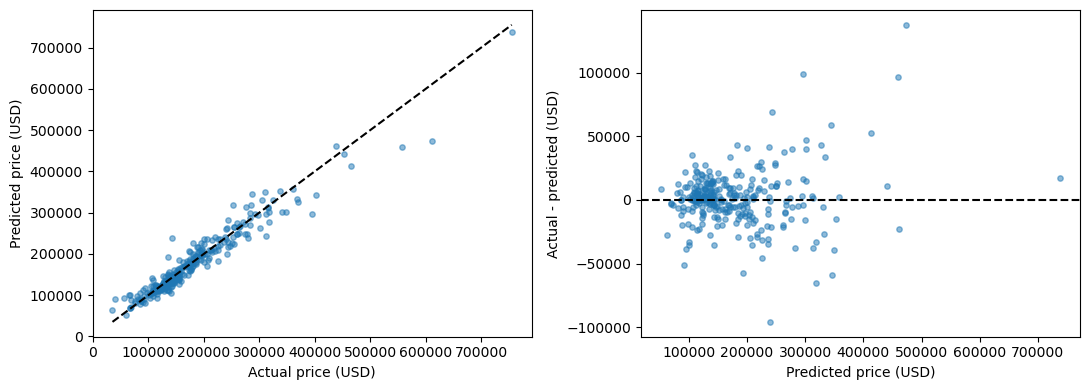

,Id,GrLivArea,OverallQual,Neighborhood,YearBuilt,YearRemodAdd,TotalBsmtSF,GarageCars,actual_USD,predicted_USD,signed_error_USD,absolute_error_USD,cause_review
178,899,2364,9,NridgHt,2009,2010,2330,3,611657.0,473938.317166,137718.682834,137718.682834,需依房屋特徵與 training 範圍確認；原因不能只由價格猜測
156,775,1973,8,NridgHt,2006,2006,1935,3,395000.0,295840.366906,99159.633094,99159.633094,需依房屋特徵與 training 範圍確認；原因不能只由價格猜測
213,1047,2868,9,StoneBr,2005,2006,1992,3,556581.0,459516.386960,97064.613040,97064.613040,需依房屋特徵與 training 範圍確認；原因不能只由價格猜測


In [11]:
context=['Id','GrLivArea','OverallQual','Neighborhood','YearBuilt','YearRemodAdd','TotalBsmtSF','GarageCars']
errors=test[context].copy()
errors['actual_USD']=y_test
errors['predicted_USD']=final_pred
errors['signed_error_USD']=y_test-final_pred
errors['absolute_error_USD']=np.abs(y_test-final_pred)
errors['cause_review']='需依房屋特徵與 training 範圍確認；原因不能只由價格猜測'
errors.sort_values('absolute_error_USD',ascending=False).head(10).to_csv(
    FINAL_OUTPUT/'large_error_cases.csv',index=False,encoding='utf-8-sig')
area_cut=train.GrLivArea.quantile([1/3,2/3]).to_numpy()
slices={'area':pd.cut(test.GrLivArea,[-np.inf,*area_cut,np.inf],labels=['small','medium','large']),
        'quality':pd.cut(test.OverallQual,[-np.inf,5,7,np.inf],labels=['<=5','6-7','>=8'])}
slice_rows=[]
for kind,labels in slices.items():
    for label in labels.cat.categories:
        mask=labels.eq(label).to_numpy()
        for name in [FINAL_MODEL,'RandomForest']:
            pred=test_predictions[name+'_predicted_USD'].to_numpy()[mask]
            actual=y_test.to_numpy()[mask]
            if len(actual):slice_rows.append({'slice':kind,'group':str(label),'model':name,
                'n':len(actual),'MAE_USD':mean_absolute_error(actual,pred),
                'RMSE_USD':np.sqrt(mean_squared_error(actual,pred))})
pd.DataFrame(slice_rows).to_csv(FINAL_OUTPUT/'slice_metrics.csv',index=False,encoding='utf-8-sig')
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(y_test,final_pred,s=15,alpha=.5)
lims=[min(y_test.min(),final_pred.min()),max(y_test.max(),final_pred.max())]
axes[0].plot(lims,lims,'k--');axes[0].set(xlabel='Actual price (USD)',ylabel='Predicted price (USD)')
axes[1].scatter(final_pred,y_test-final_pred,s=15,alpha=.5)
axes[1].axhline(0,color='k',linestyle='--');axes[1].set(xlabel='Predicted price (USD)',ylabel='Actual - predicted (USD)')
fig.tight_layout();fig.savefig(FINAL_FIGURES/'final_predictions_residuals.png',dpi=180)
plt.show()
display(errors.sort_values('absolute_error_USD',ascending=False).head(3))


## 6. Final Test 結果與解讀

| 模型 | Test MAE USD | Test RMSE USD | Test R² | 通過 15,000 MAE 門檻 |
|---|---:|---:|---:|---:|
| Mean | 62,580.40 | 87,619.50 | -0.0009 | 否 |
| Single-feature OLS | 38,473.84 | 57,594.46 | 0.5675 | 否 |
| Random Forest | 16,383.85 | 27,017.93 | 0.9048 | 否 |
| **Elastic Net** | **14,422.74** | **22,340.04** | **0.9349** | **是** |

Elastic Net 相較 Random Forest 的 MAE 平均改善 1,961.11 USD。以 final−RandomForest 定義 gap，估計為 -1,961.11 USD，paired bootstrap 95% CI [-3,846.87, -399.02]，paired permutation p=0.0170。結果支持 Final Model 在此測試集的絕對誤差較低。

最大三筆誤差為 Id 899（137,718.68 USD）、775（99,159.63 USD）、1047（97,064.61 USD），均為高品質且價格較高的住宅。品質 ≥8 組 MAE 27,635.58 USD，高於品質 ≤5 組的 11,085.37 USD；主要剩餘風險集中在高價、高品質與大坪數房屋。

係數表含 214 個 encoded predictors。29 個 bootstrap 95% CI 未跨 0；完整 one-hot 與相關特徵使許多 VIF 為 inf，QualityArea 與 GrLivArea 的 VIF 約 33.10 與 57.72。這支持正則化選擇，但係數、CI 與 p-value 僅為固定 preprocessing/features/hyperparameters 下的探索性診斷，不作因果解釋。

Notebook schema、輸出數字與 292 筆預測已重新計算核對；指標差異低於 1.5×10⁻¹¹，且沒有 error output。